# Ghost Pharmacies

When Bay Area pharmacies closed, did people in cheaper homes lose their nearest pharmacy more often?

This one notebook goes from the raw files in `data/` to every number, chart and map we report.
**Rule:** before submitting, do *Runtime → Restart and run all* (or `Kernel → Restart & Run All`) and make sure it finishes without errors.

Build steps follow the Team Master Guide. Combined from Ethan's and Brian's notebooks (Ethan: Steps 1, 2, 6, 8. Brian: Steps 4, 5, 7, 9. Shared: Step 3, 10).

Inputs: the raw files in `data/`, plus `outputs/handcheck_done.csv` (our Google Maps hand-check answers, typed by hand in Step 3).

## Step 0. Setup
Runs in both Google Colab and a local Jupyter. Edit only the paths in this cell.

In [1]:
import os, sys, random
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "folium"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
    # Shared Drive folder that holds the raw files and receives outputs. Change if yours differs.
    PROJECT_DIR = Path("/content/drive/MyDrive/ghost-pharmacies")
else:
    # Local: the repository root (this notebook lives in notebooks/).
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR = PROJECT_DIR / "data"        # raw files, never edited
OUT_DIR = PROJECT_DIR / "outputs"      # everything the notebook creates
FIG_DIR = OUT_DIR / "figures"
MAP_DIR = OUT_DIR / "maps"
for d in (OUT_DIR, FIG_DIR, MAP_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Raw file names. Rename here if the event files are named differently.
PLACES_CSV = DATA_DIR / "google_maps.csv"
ZILLOW_CSVS = [DATA_DIR / n for n in ["Zillow_part1.csv", "zillow_part2.csv", "zillow_part3.csv"]]   # full Zillow file, in parts: read all and concatenate
CENSUS_CSV = DATA_DIR / "census_tracts.csv"   # optional

# One seed, used everywhere (train/test split, sampling, models).
SEED = 42
random.seed(SEED)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import folium

np.random.seed(SEED)
pd.set_option("display.max_columns", 50)

print("Colab" if IN_COLAB else "Local", "| project dir:", PROJECT_DIR)
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| sklearn", sklearn.__version__, "| folium", folium.__version__)

Local | project dir: /Users/eriggins/IdeaProjects/ghost-pharmacies
python 3.11.9 | pandas 3.1.1 | numpy 2.4.6 | sklearn 1.9.1 | folium 0.20.0


### Check the raw files
Confirms each file is in place and has the columns the guide relies on. Reads only the header row, so it is fast even on the 500 MB file.

In [2]:
ZILLOW_COLS = ["zpid", "latitude", "longitude", "county", "bedrooms", "homeStatus", "price",
               "rentZestimate", "getting_around_scores"]
EXPECTED = {
    PLACES_CSV: ["place_id", "name", "category", "lat", "lon", "permanently_closed", "top_reviews"],
    **{p: ZILLOW_COLS for p in ZILLOW_CSVS},
}

for path, cols in EXPECTED.items():
    if not path.exists():
        print(f"MISSING  {path.name}: put it in {DATA_DIR}")
        continue
    header = pd.read_csv(path, nrows=0).columns
    missing = [c for c in cols if c not in header]
    size_mb = path.stat().st_size / 1e6
    status = "OK      " if not missing else "CHECK   "
    print(f"{status} {path.name} ({size_mb:,.0f} MB, {len(header)} columns)"
          + (f" missing: {missing}" if missing else ""))

print("Census (optional):", "found" if CENSUS_CSV.exists() else "not added")

OK       google_maps.csv (506 MB, 41 columns)
OK       Zillow_part1.csv (1,495 MB, 140 columns)
OK       zillow_part2.csv (3,934 MB, 140 columns)
OK       zillow_part3.csv (2,006 MB, 140 columns)
Census (optional): not added


## Step 1. Build the pharmacy table
Owner: Ethan  
Load Places with `usecols`, keep `category == 'Pharmacy'` (expect about 1,694), add the `chain` column, print closures per chain and compare with the guide.

In [3]:
cols = ['place_id', 'name', 'category', 'lat', 'lon', 'permanently_closed', 'top_reviews'] # get needed columns
p = pd.read_csv(PLACES_CSV, usecols=cols, low_memory=False)
print(len(p))

pharmacies = p[p.category == 'Pharmacy'].copy()
print(len(pharmacies), pharmacies.permanently_closed.sum()) #num pharmacies and num closed

# chains table
CHAINS = [
    ('Walgreens', ['walgreens']),
    ('CVS', ['cvs', 'target']),
    ('Rite Aid', ['rite aid']),
    ('Lucky', ['lucky', 'save mart']),
    ('Safeway', ['safeway']),
    ('Costco', ['costco']),
    ('Walmart', ['walmart']),
    ('Kaiser', ['kaiser']),
    ('Rayleys', ['raley', 'nob hill']), ]

# if chain keywords appear in name, identify as a chain
def chain_of(name):
    n = str(name).lower()
    for chain, keys in CHAINS:
        if any(k in n for k in keys):
            return chain
    return 'Independent'
pharmacies['chain'] = pharmacies['name'].apply(chain_of)
pharmacies.drop(columns='top_reviews').head(10)

147429
1692 524


,place_id,name,category,lat,lon,permanently_closed,chain
44,ChIJJ7Ibd1t8j4ARZ2FG0Xw7Y_s,Walgreens Pharmacy,Pharmacy,37.700780,-122.484303,False,Walgreens
128,ChIJMfTsjB9nhYAR6n_6ZjC7bYQ,Diablo Professional Pharmacy,Pharmacy,37.984643,-122.036154,True,Independent
337,ChIJq6o2ZguQhYAREvFyBFAIWt4,Pharmaca Integrative Pharmacy,Pharmacy,37.904155,-122.542290,True,Independent
509,ChIJeWbogxgyjoART71-F7zRwY0,Safeway Pharmacy,Pharmacy,37.267140,-121.833175,False,Safeway
571,ChIJDzdZCOZvhYARO8EgyzmimLQ,Rite Aid Pharmacy,Pharmacy,38.054624,-122.155252,True,Rite Aid
691,ChIJy-NyFsWPj4ARGN85LlnT8VQ,Medical Arts Pharmacy,Pharmacy,37.714412,-122.142271,False,Independent
858,ChIJk_jA5oUgjoAR8jz3mH9C540,Walgreens Pharmacy,Pharmacy,37.129916,-121.638607,False,Walgreens
861,ChIJC5cXpzeQj4ARZCRQ_sy53tA,Walgreens Pharmacy,Pharmacy,37.685806,-122.138247,False,Walgreens
971,ChIJs2suXUCij4ARIAN1d1HeY5o,Rph,Pharmacy,37.500029,-122.241142,False,Independent
1061,ChIJDe8uw6Z-hYARGsgDDkGZbP0,CVS Pharmacy,Pharmacy,37.881282,-122.269022,False,CVS


## Step 2. Decide which closures are real
Owner: Ethan  
Distance from each closed pharmacy to the nearest open one (BallTree, haversine). Real closure = not Rite Aid or Lucky and no open pharmacy within 50 m (expect about 358). Save `outputs/pharmacies_clean.csv`.

In [4]:
def distance(lat1, lon1, lat2, lon2): #haversine formula -> distance in meters between two lat/lon points on earth
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2]) # convert to radians
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2 #distance between two points on sphere
    return 2 * 6371000 * np.arcsin(np.sqrt(a)) # turn a into meters

pharmacies = pharmacies.dropna(subset=['lat', 'lon']).copy() #pharmacies with no coordinates
open_pharm = pharmacies[pharmacies.permanently_closed == False] #tables of pharmacies still open

def nearest_open(row):
    return distance(row.lat, row.lon, open_pharm.lat.values, open_pharm.lon.values).min()

closed = pharmacies.permanently_closed == True 
pharmacies.loc[closed, 'm_to_open'] = pharmacies[closed].apply(nearest_open, axis=1) # for closed pharmacies store meters to the nearest open pharmacy

pharmacies['chain_shutdown'] = pharmacies.chain.isin(['Rite Aid', 'Lucky']) #flag rite aid and lucky as chain shutdown
pharmacies['real_closure'] = closed & ~pharmacies.chain_shutdown & (pharmacies.m_to_open > 50) # real closure -> closed, not a chain shutdown, no open pharmacy within 50m

print(closed.sum(), pharmacies.real_closure.sum())
pharmacies.to_csv(OUT_DIR / 'pharmacies_clean.csv', index=False)
    

524 358


## Step 3. Hand-check
Owner: Ethan and Brian  
30 real closures + 10 open pharmacies sampled with `SEED`, checked on Google Maps. Load the results table here and report the error rate.

In [5]:
sample = pd.concat([
    pharmacies[pharmacies.real_closure].sample(30, random_state=SEED),
    pharmacies[pharmacies.permanently_closed == False].sample(10, random_state=SEED),
]) #random sample
sample[['name', 'chain', 'lat', 'lon', 'real_closure']].to_csv(OUT_DIR / 'handcheck.csv', index=False) 
#handchecked_done is in outputs

In [6]:
# scoring cell

done = pd.read_csv(OUT_DIR / 'handcheck_done.csv')
wrong = (done['correct'].str.lower() == 'no').sum() 
print(f"{wrong} wrong out of {len(done)} = {wrong / len(done):.0%} error rate")

2 wrong out of 40 = 5% error rate


## Step 4. Build the rent level
Owner: Brian  
Load Zillow (use `chunksize` if needed), drop missing coordinates, compute rent and relative rent by bedrooms, keep \$500 to \$20,000 and 0 to 5 bedrooms, split into thirds within county.

In [7]:
# 4.1: processing the 3 zillow files into 1 table
pieces = []
for i in range(len(ZILLOW_CSVS)):
    reader = pd.read_csv(ZILLOW_CSVS[i], usecols=ZILLOW_COLS, chunksize=50000)
    for chunk in reader:
        chunk["row_source"] = i + 1 # tagging each row for easy reference to its file origin
        pieces.append(chunk)
mergedTable = pd.concat(pieces, ignore_index=True)

In [8]:
# confirmation of 4.1 implementation
display(mergedTable.head(10))
print(len(mergedTable))
print(mergedTable.dtypes)
print(mergedTable["zpid"].duplicated().sum())
print(mergedTable["row_source"].value_counts())

,zpid,homeStatus,bedrooms,price,longitude,latitude,rentZestimate,county,getting_around_scores,row_source
0,2073071533,FOR_RENT,2.0,5094,-122.263677,37.510161,NaN,San Mateo County,"{""bike_score"":""66/100 | Bikeable"",""transit_sco...",1
1,2077933815,FOR_RENT,3.0,5614,-122.025500,37.376560,NaN,Santa Clara County,"{""bike_score"":""84/100 | Very Bikeable"",""transi...",1
2,19253238,RECENTLY_SOLD,4.0,1850000,-122.532330,37.922455,NaN,Marin County,"{""bike_score"":""43/100 | Somewhat Bikeable"",""tr...",1
3,326139325,RECENTLY_SOLD,1.0,749000,-122.456100,37.764890,5221.0,San Francisco County,"{""bike_score"":""67/100 | Bikeable"",""transit_sco...",1
4,2089306902,FOR_RENT,3.0,5819,-121.932376,37.347085,NaN,Santa Clara County,"{""bike_score"":""79/100 | Very Bikeable"",""transi...",1
5,2067771850,FOR_RENT,0.0,2095,-122.415020,37.788602,NaN,San Francisco County,"{""bike_score"":""70/100 | Very Bikeable"",""transi...",1
6,19278440,RECENTLY_SOLD,3.0,679000,-122.570625,38.117126,3929.0,Marin County,"{""bike_score"":""29/100 | Somewhat Bikeable"",""tr...",1
7,299071045,RECENTLY_SOLD,4.0,840000,-122.024370,37.596542,2963.0,Alameda County,"{""bike_score"":""59/100 | Bikeable"",""transit_sco...",1
8,18402887,RECENTLY_SOLD,4.0,1150000,-122.088776,37.949580,5115.0,Contra Costa County,"{""bike_score"":""51/100 | Bikeable"",""transit_sco...",1
9,18384685,RECENTLY_SOLD,4.0,1452000,-122.036670,37.931816,4582.0,Contra Costa County,"{""bike_score"":""86/100 | Very Bikeable"",""transi...",1


148005
zpid                       int64
homeStatus                   str
bedrooms                 float64
price                      int64
longitude                float64
latitude                 float64
rentZestimate            float64
county                       str
getting_around_scores        str
row_source                 int64
dtype: object
0
row_source
2    78424
3    39867
1    29714
Name: count, dtype: int64


In [9]:
# 4.2: visualizing data before changing anything
print(mergedTable["homeStatus"].value_counts())
print(mergedTable["county"].value_counts())
print(mergedTable.isna().mean())
print(mergedTable.groupby("homeStatus")["price"].median())

homeStatus
FOR_RENT         74343
RECENTLY_SOLD    61606
FOR_SALE         12056
Name: count, dtype: int64
county
Santa Clara County      38559
Alameda County          34588
Contra Costa County     19512
San Francisco County    15652
San Mateo County        13702
Sonoma County           10216
Solano County            8442
Marin County             4474
Napa County              2860
Name: count, dtype: int64
zpid                     0.000000
homeStatus               0.000000
bedrooms                 0.015452
price                    0.000000
longitude                0.005371
latitude                 0.005371
rentZestimate            0.513354
county                   0.000000
getting_around_scores    0.000000
row_source               0.000000
dtype: float64
homeStatus
FOR_RENT            3109.0
FOR_SALE          949000.0
RECENTLY_SOLD    1103500.0
Name: price, dtype: float64


In [10]:
# 4.3: Clean data, drop homes w no locations
homes = mergedTable.dropna(subset=["longitude", "latitude"])
print("rows after:", len(homes))


rows after: 147210


In [11]:
# 4.4: compute rent
homes["rent"] = np.where(homes["homeStatus"] == "FOR_RENT", homes["price"], homes["rentZestimate"])
print(homes["rent"].isna().groupby(homes["homeStatus"]).mean())

# 4.5: filter out noise
# keep contains T/F list that lines up with the rows of homes, rows that line up with F are dropped from homes
keep = homes["rent"].between(500, 20000) & homes["bedrooms"].between(0, 5)
homes = homes[keep]
# sanity check
print("rows after 4.5:", len(homes))
homes["homeStatus"].value_counts()


homeStatus
FOR_RENT         0.000000
FOR_SALE         0.302618
RECENTLY_SOLD    0.086632
Name: rent, dtype: float64
rows after 4.5: 134835


homeStatus
FOR_RENT         73519
RECENTLY_SOLD    53588
FOR_SALE          7728
Name: count, dtype: int64

In [12]:
# 4.6: relative rent price so we can more accurately map what is a "cheap home"
# groupby to sort rows into groups by # beds, specified that the rent values are the values in the groups, then got the median
homes["rel_rent"] = homes["rent"] / homes.groupby("bedrooms")["rent"].transform("median")
display(homes.head(10))
# sanity check
print(homes.groupby("bedrooms")["rent"].agg(["count", "median"]))


# 4.7: label each homes rel rent by low, middle, high comparative to county so we can analyze impact of closing pharmas
prcnt_by_row = homes.groupby("county")["rel_rent"].rank(pct=True, method="first") # rank gives percentile of the rel_rent relative to the group
homes["rent_tier"] = pd.cut(prcnt_by_row, bins=[0, 1/3, 2/3, 1], labels=["low", "middle", "high"]) # sorts the prcnts into the labels and makes a new col
display(homes.head(10))
# sanity check
print(len(prcnt_by_row) == len(homes))
print(pd.crosstab(homes["county"], homes["rent_tier"]))
print(homes["rent_tier"].isna().sum())

,zpid,homeStatus,bedrooms,price,longitude,latitude,rentZestimate,county,getting_around_scores,row_source,rent,rel_rent
0,2073071533,FOR_RENT,2.0,5094,-122.263677,37.510161,NaN,San Mateo County,"{""bike_score"":""66/100 | Bikeable"",""transit_sco...",1,5094.0,1.482106
1,2077933815,FOR_RENT,3.0,5614,-122.025500,37.376560,NaN,Santa Clara County,"{""bike_score"":""84/100 | Very Bikeable"",""transi...",1,5614.0,1.337622
3,326139325,RECENTLY_SOLD,1.0,749000,-122.456100,37.764890,5221.0,San Francisco County,"{""bike_score"":""67/100 | Bikeable"",""transit_sco...",1,5221.0,1.802831
4,2089306902,FOR_RENT,3.0,5819,-121.932376,37.347085,NaN,Santa Clara County,"{""bike_score"":""79/100 | Very Bikeable"",""transi...",1,5819.0,1.386467
5,2067771850,FOR_RENT,0.0,2095,-122.415020,37.788602,NaN,San Francisco County,"{""bike_score"":""70/100 | Very Bikeable"",""transi...",1,2095.0,0.859664
6,19278440,RECENTLY_SOLD,3.0,679000,-122.570625,38.117126,3929.0,Marin County,"{""bike_score"":""29/100 | Somewhat Bikeable"",""tr...",1,3929.0,0.936145
7,299071045,RECENTLY_SOLD,4.0,840000,-122.024370,37.596542,2963.0,Alameda County,"{""bike_score"":""59/100 | Bikeable"",""transit_sco...",1,2963.0,0.602358
8,18402887,RECENTLY_SOLD,4.0,1150000,-122.088776,37.949580,5115.0,Contra Costa County,"{""bike_score"":""51/100 | Bikeable"",""transit_sco...",1,5115.0,1.039845
9,18384685,RECENTLY_SOLD,4.0,1452000,-122.036670,37.931816,4582.0,Contra Costa County,"{""bike_score"":""86/100 | Very Bikeable"",""transi...",1,4582.0,0.931490
11,2055832490,FOR_RENT,1.0,2195,-122.098081,37.395047,NaN,Santa Clara County,"{""bike_score"":null,""transit_score"":""45/100 | S...",1,2195.0,0.757942


          count  median
bedrooms               
0.0        7876  2437.0
1.0       34744  2896.0
2.0       42133  3437.0
3.0       28442  4197.0
4.0       17027  4919.0
5.0        4613  5747.0


,zpid,homeStatus,bedrooms,price,longitude,latitude,rentZestimate,county,getting_around_scores,row_source,rent,rel_rent,rent_tier
0,2073071533,FOR_RENT,2.0,5094,-122.263677,37.510161,NaN,San Mateo County,"{""bike_score"":""66/100 | Bikeable"",""transit_sco...",1,5094.0,1.482106,high
1,2077933815,FOR_RENT,3.0,5614,-122.025500,37.376560,NaN,Santa Clara County,"{""bike_score"":""84/100 | Very Bikeable"",""transi...",1,5614.0,1.337622,high
3,326139325,RECENTLY_SOLD,1.0,749000,-122.456100,37.764890,5221.0,San Francisco County,"{""bike_score"":""67/100 | Bikeable"",""transit_sco...",1,5221.0,1.802831,high
4,2089306902,FOR_RENT,3.0,5819,-121.932376,37.347085,NaN,Santa Clara County,"{""bike_score"":""79/100 | Very Bikeable"",""transi...",1,5819.0,1.386467,high
5,2067771850,FOR_RENT,0.0,2095,-122.415020,37.788602,NaN,San Francisco County,"{""bike_score"":""70/100 | Very Bikeable"",""transi...",1,2095.0,0.859664,low
6,19278440,RECENTLY_SOLD,3.0,679000,-122.570625,38.117126,3929.0,Marin County,"{""bike_score"":""29/100 | Somewhat Bikeable"",""tr...",1,3929.0,0.936145,low
7,299071045,RECENTLY_SOLD,4.0,840000,-122.024370,37.596542,2963.0,Alameda County,"{""bike_score"":""59/100 | Bikeable"",""transit_sco...",1,2963.0,0.602358,low
8,18402887,RECENTLY_SOLD,4.0,1150000,-122.088776,37.949580,5115.0,Contra Costa County,"{""bike_score"":""51/100 | Bikeable"",""transit_sco...",1,5115.0,1.039845,high
9,18384685,RECENTLY_SOLD,4.0,1452000,-122.036670,37.931816,4582.0,Contra Costa County,"{""bike_score"":""86/100 | Very Bikeable"",""transi...",1,4582.0,0.931490,high
11,2055832490,FOR_RENT,1.0,2195,-122.098081,37.395047,NaN,Santa Clara County,"{""bike_score"":null,""transit_score"":""45/100 | S...",1,2195.0,0.757942,low


True
rent_tier               low  middle   high
county                                    
Alameda County        10869   10870  10870
Contra Costa County    6079    6079   6080
Marin County           1255    1255   1256
Napa County             788     788    788
San Francisco County   4541    4542   4542
San Mateo County       3928    3928   3928
Santa Clara County    11866   11867  11867
Solano County          2629    2629   2630
Sonoma County          2987    2987   2987
0


In [13]:
# 4.8: create col for numeric walk score values, if none put NaN
pattern = r'"walk_score":"(\d+)/100'
homes["walk_score"] = homes["getting_around_scores"].str.extract(pattern, expand=False).astype(float) # extractin regex pattern as a collection, turned into floats, and added to new col
display(homes.sample(n=10, random_state=SEED)
)
# sanity check
print(homes["walk_score"].describe(), "\n")
print("percent with walk score:", homes["walk_score"].notna().mean())

,zpid,homeStatus,bedrooms,price,longitude,latitude,rentZestimate,county,getting_around_scores,row_source,rent,rel_rent,rent_tier,walk_score
71847,18304544,RECENTLY_SOLD,3.0,580000,-121.762320,37.955220,2956.0,Contra Costa County,"{""bike_score"":""40/100 | Somewhat Bikeable"",""tr...",2,2956.0,0.704313,low,25.0
128387,19390448,FOR_SALE,3.0,599000,-122.300156,38.312790,3294.0,Napa County,"{""bike_score"":""88/100 | Very Bikeable"",""transi...",3,3294.0,0.784846,low,83.0
134598,2079194705,FOR_RENT,2.0,4097,-121.998373,37.351045,NaN,Santa Clara County,"{""bike_score"":null,""transit_score"":null,""walk_...",3,4097.0,1.192028,middle,NaN
18432,2068396530,FOR_RENT,1.0,3100,-122.251891,37.865259,NaN,Alameda County,"{""bike_score"":""76/100 | Very Bikeable"",""transi...",1,3100.0,1.070442,high,87.0
42818,18366259,RECENTLY_SOLD,3.0,675000,-122.045220,37.960930,3654.0,Contra Costa County,"{""bike_score"":""73/100 | Very Bikeable"",""transi...",2,3654.0,0.870622,middle,68.0
75069,19859251,FOR_RENT,4.0,4999,-121.596990,37.006252,4682.0,Santa Clara County,"{""bike_score"":""44/100 | Somewhat Bikeable"",""tr...",2,4999.0,1.016263,low,42.0
147510,18304746,RECENTLY_SOLD,3.0,580000,-121.765990,37.957684,3202.0,Contra Costa County,"{""bike_score"":""38/100 | Somewhat Bikeable"",""tr...",3,3202.0,0.762926,low,21.0
97819,19619999,RECENTLY_SOLD,2.0,1140000,-122.028310,37.336967,4515.0,Santa Clara County,"{""bike_score"":""76/100 | Very Bikeable"",""transi...",2,4515.0,1.313646,high,52.0
37700,15667660,FOR_SALE,2.0,440000,-122.213340,38.109380,2443.0,Solano County,"{""bike_score"":""50/100 | Bikeable"",""transit_sco...",2,2443.0,0.710794,middle,74.0
21454,301028912,RECENTLY_SOLD,4.0,720000,-121.703420,37.982536,3845.0,Contra Costa County,"{""bike_score"":""34/100 | Somewhat Bikeable"",""tr...",1,3845.0,0.781663,middle,16.0


count    114032.000000
mean         59.872343
std          28.030395
min           0.000000
25%          40.000000
50%          64.000000
75%          83.000000
max         100.000000
Name: walk_score, dtype: float64 

percent with walk score: 0.8457151333110839


In [14]:
# 4.8 check: 15% no walk score? is that a pattern mess up or truly missing data

miss = homes.loc[homes["walk_score"].isna(), "getting_around_scores"]

n_missing     = len(miss)
n_empty_col   = miss.isna().sum()                                                # whole column empty
n_null_walk   = miss.str.contains('"walk_score":null', regex=False).sum()        # walk score explicitly null
n_unexplained = n_missing - n_empty_col - n_null_walk

print("homes with no walk_score:     ", n_missing)
print("  getting_around_scores empty:", n_empty_col)
print("  walk_score is null in text: ", n_null_walk)
print("  unexplained (possible miss):", n_unexplained)
print("dtype:", homes["walk_score"].dtype)

# Show a few unexplained rows in full so we can see how they're written
unexplained = miss[miss.notna() & ~miss.str.contains('"walk_score":null', regex=False)]
for s in unexplained.head(3):
    print("\n", s)

homes with no walk_score:      20803
  getting_around_scores empty: 0
  walk_score is null in text:  20803
  unexplained (possible miss): 0
dtype: float64


In [15]:
# 4.9: save the verified-"good" clean homes table for use

KEEP = ["zpid", "latitude", "longitude", "county", "bedrooms", "homeStatus",
        "rent", "rel_rent", "rent_tier", "walk_score"]
homes_out = homes[KEEP]

# Checks before saving: stop loudly if anything is wrong
for col in ["rent", "rel_rent", "rent_tier", "latitude", "longitude"]:
    assert homes_out[col].isna().sum() == 0, f"missing values in {col}"
assert homes_out["county"].nunique() == 9, "expected 9 counties"
assert homes_out["rent_tier"].nunique() == 3, "expected 3 rent tiers"
assert homes_out["zpid"].is_unique, "duplicate zpid found"
assert homes_out["walk_score"].dropna().between(0, 100).all(), "walk_score outside 0-100"

# Save, then reload to prove the file matches memory
HOMES_CSV = OUT_DIR / "homes_clean.csv"
homes_out.to_csv(HOMES_CSV, index=False)

reloaded = pd.read_csv(HOMES_CSV)
assert len(reloaded) == len(homes_out), "row count changed on reload"
assert list(reloaded.columns) == KEEP, "columns changed on reload"

print("saved:", HOMES_CSV)
print("rows:", len(reloaded), "| columns:", reloaded.shape[1])
print("walk_score filled:", round(reloaded["walk_score"].notna().mean(), 3))

saved: /Users/eriggins/IdeaProjects/ghost-pharmacies/outputs/homes_clean.csv
rows: 134835 | columns: 10
walk_score filled: 0.846


In [16]:
# 4.10: find the closest 25 homes to each pharmacy and get the median to get local_rel_rent for each pharma
from sklearn.neighbors import BallTree

# convert data to radians to make balltree, due to haversine
homes_coords = np.radians(homes_out[["latitude", "longitude"]].to_numpy())
tree = BallTree(homes_coords, metric="haversine")
# load pharm data, use id, lat and lon
pharm = pd.read_csv(OUT_DIR / "pharmacies_clean.csv")
pharm_coords = np.radians(pharm[["lat", "lon"]].to_numpy())
dist_radians, indices = tree.query(pharm_coords, k=25) # the query asks which 25 homes are nearest for the pharm_coords, returns distance and indices as arrays
# use indices to tell which homes to look at to get the rel_rent -> median rr
relRent = homes_out["rel_rent"].to_numpy() # make into array
neighbor_relRent = relRent[indices] # each index in this array = list of 25 relative rents
local_rel_rent = np.median(neighbor_relRent, axis=1)
# create the table containing place_id, local_rel_rent, distances
table = pd.DataFrame({"place_id": pharm["place_id"], "local_rel_rent": local_rel_rent, "km_to_farthest_house": dist_radians[:, 24] * 6371}) # row order was preserved
display(table.head(10))

# Sanity Checks
print("shapes:", dist_radians.shape, indices.shape, local_rel_rent.shape)
print("median km to nearest home:", np.median(dist_radians[:, 0] * 6371))
print("NaN in local_rel_rent:", np.isnan(local_rel_rent).sum())
print(table.describe())
print("pharmacies with 25th home > 2 km:", (table["km_to_farthest_house"] > 2).sum())




# save pharm_local_rent
PHARM_RENT_CSV = OUT_DIR / "pharmacy_local_rent.csv"

# Checks before saving
assert len(table) == len(pharm) == 1692, f"expected 1692 pharmacies, got {len(table)}"
assert table["place_id"].is_unique, "duplicate place_id"
assert (table["place_id"] == pharm["place_id"]).all(), "row order differs from pharmacies_clean"
assert table["local_rel_rent"].isna().sum() == 0, "missing local_rel_rent"

# Save (new file; pharmacies_clean.csv is not touched), then reload to confirm
table.to_csv(PHARM_RENT_CSV, index=False)
reloaded_pr = pd.read_csv(PHARM_RENT_CSV)
assert len(reloaded_pr) == len(table), "row count changed on reload"
assert list(reloaded_pr.columns) == list(table.columns), "columns changed on reload"

print("saved:", PHARM_RENT_CSV)
print("rows:", len(reloaded_pr), "| columns:", list(reloaded_pr.columns))

,place_id,local_rel_rent,km_to_farthest_house
0,ChIJJ7Ibd1t8j4ARZ2FG0Xw7Y_s,1.149869,0.562358
1,ChIJMfTsjB9nhYAR6n_6ZjC7bYQ,0.792233,0.521128
2,ChIJq6o2ZguQhYAREvFyBFAIWt4,1.513316,0.551101
3,ChIJeWbogxgyjoART71-F7zRwY0,0.929299,0.145209
4,ChIJDzdZCOZvhYARO8EgyzmimLQ,0.815583,0.654431
5,ChIJy-NyFsWPj4ARGN85LlnT8VQ,0.742403,0.274676
6,ChIJk_jA5oUgjoAR8jz3mH9C540,0.992435,0.534380
7,ChIJC5cXpzeQj4ARZCRQ_sy53tA,0.795568,0.509644
8,ChIJs2suXUCij4ARIAN1d1HeY5o,1.243031,1.084977
9,ChIJDe8uw6Z-hYARGsgDDkGZbP0,0.945592,0.238599


shapes: (1692, 25) (1692, 25) (1692,)
median km to nearest home: 0.16508595268740317
NaN in local_rel_rent: 0
       local_rel_rent  km_to_farthest_house
count     1692.000000           1692.000000
mean         1.044837              1.386502
std          0.310150              3.966091
min          0.431630              0.000713
25%          0.809457              0.315043
50%          0.953302              0.458214
75%          1.214068              0.664403
max          2.288333             24.698653
pharmacies with 25th home > 2 km: 96
saved: /Users/eriggins/IdeaProjects/ghost-pharmacies/outputs/pharmacy_local_rent.csv
rows: 1692 | columns: ['place_id', 'local_rel_rent', 'km_to_farthest_house']


## Step 5. Access-loss analysis
Owner: Brian  
Nearest-pharmacy distance before and after for every home, the two-sided table, with and without chain shutdowns, broken down by county.

In [17]:
# load pharmacies_clean, homes_clean, pharmacy_local_rent cv
load_ph = pd.read_csv(OUT_DIR / "pharmacies_clean.csv")
load_hm_cleaned = pd.read_csv(OUT_DIR / "homes_clean.csv")
load_ph_rent = pd.read_csv(OUT_DIR / "pharmacy_local_rent.csv")


# error catcher through assertions
# pharmacies
assert len(load_ph) == 1692, f"pharmacies: expected 1692 rows, got {len(load_ph)}"
assert load_ph["place_id"].is_unique, f"pharmacies: {load_ph['place_id'].duplicated().sum()} duplicate place_id"
n_missing = load_ph[["lat", "lon"]].isna().sum().sum()
assert n_missing == 0, f"pharmacies: {n_missing} missing lat/lon values"

# homes
assert len(load_hm_cleaned) == 134835, f"homes: expected 134835 rows, got {len(load_hm_cleaned)}"
assert load_hm_cleaned["zpid"].is_unique, f"homes: {load_hm_cleaned['zpid'].duplicated().sum()} duplicate zpid"
n_missing = load_hm_cleaned[["rent_tier", "latitude", "longitude"]].isna().sum().sum()
assert n_missing == 0, f"homes: {n_missing} missing rent_tier/latitude/longitude values"
assert load_hm_cleaned["rent_tier"].nunique() == 3, f"homes: expected 3 tiers, got {load_hm_cleaned['rent_tier'].nunique()}"
assert load_hm_cleaned["county"].nunique() == 9, f"homes: expected 9 counties, got {load_hm_cleaned['county'].nunique()}"

# pharmacy local rent (4.10)
assert len(load_ph_rent) == 1692, f"local rent: expected 1692 rows, got {len(load_ph_rent)}"
n_missing = load_ph_rent["local_rel_rent"].isna().sum()
assert n_missing == 0, f"local rent: {n_missing} missing local_rel_rent"
n_unmatched = (~load_ph_rent["place_id"].isin(load_ph["place_id"])).sum()
assert n_unmatched == 0, f"local rent: {n_unmatched} place_ids not found in pharmacies_clean"

# summary for the record
print("pharmacies:", len(load_ph), "| homes:", len(load_hm_cleaned), "| local rent:", len(load_ph_rent))
print("homes per rent tier:", load_hm_cleaned["rent_tier"].value_counts().to_dict())
print("counties:", load_hm_cleaned["county"].nunique())

pharmacies: 1692 | homes: 134835 | local rent: 1692
homes per rent tier: {'high': 44948, 'middle': 44945, 'low': 44942}
counties: 9


In [18]:
# 5.1: pharmacy flags for picking out the 3 pharmacy sets we need later + sanity check thru the ledger

# flags must be True/False, or ~ and & give wrong sets silently
for col in ["permanently_closed", "chain_shutdown", "real_closure"]:
    assert load_ph[col].dtype == bool, f"{col} is {load_ph[col].dtype}, expected bool"

is_closed = load_ph["permanently_closed"]
is_open   = ~is_closed
is_chain  = load_ph["chain_shutdown"]          # Rite Aid or Lucky
is_real   = load_ph["real_closure"]
near_open = load_ph["m_to_open"] <= 50         # NaN (open rows) -> False

ledger = pd.DataFrame([
    ("all pharmacies",                            len(load_ph),                              1692),
    ("open",                                      is_open.sum(),                             1168),
    ("closed",                                    is_closed.sum(),                            524),
    ("  real closures",                           is_real.sum(),                              358),
    ("  duplicates (open pharmacy within 50 m)",  (is_closed & ~is_chain & near_open).sum(),   51),
    ("  Rite Aid / Lucky closures",               (is_closed & is_chain).sum(),               115),
    ("open Rite Aid / Lucky (kept as open)",      (is_open & is_chain).sum(),                   3),
], columns=["set", "count", "expected"])
ledger["match"] = ledger["count"] == ledger["expected"]
display(ledger)

assert ledger["match"].all(), "ledger mismatch: see the table above"
print("5.1 flags OK \n")




# 5.2: narrowing down pharmacies_clean.csv to the 3 sets we need, after_set, before_excl, before_incl
after_closures = load_ph[is_open].copy() # current status of pharm
before_closures = load_ph[is_open | is_real].copy()
before_closures_plus = load_ph[(is_open | is_real) | (is_closed & is_chain & ~near_open)].copy()

# 5.2 check the set sizes they should be
for name, df, expected in [("after", after_closures, 1168),
                           ("before_excl", before_closures, 1526),
                           ("before_incl", before_closures_plus, 1635)]:
    print(f"{name}: {len(df)} (expected {expected})")
    assert len(df) == expected, f"{name}: got {len(df)}, expected {expected}"
print("5.2 sets OK")

,set,count,expected,match
0,all pharmacies,1692,1692,True
1,open,1168,1168,True
2,closed,524,524,True
3,real closures,358,358,True
4,duplicates (open pharmacy within 50 m),51,51,True
5,Rite Aid / Lucky closures,115,115,True
6,open Rite Aid / Lucky (kept as open),3,3,True


5.1 flags OK 

after: 1168 (expected 1168)
before_excl: 1526 (expected 1526)
before_incl: 1635 (expected 1635)
5.2 sets OK


*After loading the data (5.0) and checking the closure flags (5.1), we split the pharmacies into three sets: after_closures, the pharmacies open today; before_closures, the open ones plus the 358 real closures; and before_closures_plus, which also adds back the 109 Rite Aid and Lucky closures with no open pharmacy within 50 m, so we can show the result doesn’t depend on leaving those company-wide shutdowns out. In 5.3, every home measures its distance to the nearest pharmacy in each set, so comparing “after” with each “before” shows which homes lost their nearest pharmacy.*

In [19]:
# 5.3: for every home, find out how far away the closest pharm is (do it for all 3 sets you got)
# helper function that finds closest pharm for every home
def nearest_pharm(homes, pharm):
    pharm_rad = np.radians(pharm[["lat", "lon"]].to_numpy())
    homes_rad = np.radians(homes[["latitude", "longitude"]].to_numpy())
    tree = BallTree(pharm_rad, metric="haversine") # tree.query will find the nearest pharma for every value in homes_rad, very large dataset 
    dist_rad, idx = tree.query(homes_rad, k=1) # gets the rad distance from pharma and the row positions of the pharmacies
    # will be using [:, 0] in order to turn 2 d array output from tree.query into 1d array
    meters = dist_rad[:, 0] * 6371 * 1000
    place_ids = pharm["place_id"].to_numpy()[idx[:, 0]] # the part at the end means fancy indexing, swap each pharmacy position for its place_id; result stays in home order
    return meters, place_ids

# one call per pharmacy set; "after" doesn't need the place_id, so _ discards it
load_hm_cleaned["m_after"], _ = nearest_pharm(load_hm_cleaned, after_closures)
load_hm_cleaned["m_before_excl"], load_hm_cleaned["pid_before_excl"] = nearest_pharm(load_hm_cleaned, before_closures)
load_hm_cleaned["m_before_incl"], load_hm_cleaned["pid_before_incl"] = nearest_pharm(load_hm_cleaned, before_closures_plus)
# example: if idx[:, 0] = [2, 0, 2] and the place_ids are [CVS, Walgreens, Safeway],
# the result is [Safeway, CVS, Safeway]: home 0's nearest is Safeway, home 1's is CVS, home 2's is Safeway


dist_cols = ["m_after", "m_before_excl", "m_before_incl"]

# check 1, units: medians should be hundreds of metres, not 0.0001 or thousands of km
print(load_hm_cleaned[dist_cols].describe())

# check 2, order: adding pharmacies can only make the nearest one closer
bad_incl = (load_hm_cleaned["m_before_incl"] > load_hm_cleaned["m_before_excl"] + 1e-6).sum()
bad_excl = (load_hm_cleaned["m_before_excl"] > load_hm_cleaned["m_after"] + 1e-6).sum()
print("order violations:", bad_incl, bad_excl, "(both must be 0)")
assert bad_incl == 0 and bad_excl == 0, "a 'before' distance is longer than a smaller set's distance"

# check 3, by hand: brute-force one home against every open pharmacy with Step 2's distance()
h = load_hm_cleaned.iloc[0]
brute = distance(h["latitude"], h["longitude"], after_closures["lat"], after_closures["lon"]).min()
print(f"home 0: BallTree {h['m_after']:.1f} m vs brute force {brute:.1f} m")
assert abs(brute - h["m_after"]) < 1, "BallTree and brute force disagree"

# check 4, rows: no home lost
assert len(load_hm_cleaned) == 134835, f"homes: {len(load_hm_cleaned)}"
assert load_hm_cleaned[dist_cols].isna().sum().sum() == 0, "missing distances"
print("5.3 distances OK")

             m_after  m_before_excl  m_before_incl
count  134835.000000  134835.000000  134835.000000
mean     1085.277220     965.833749     931.981174
std      1617.709628    1252.587941    1239.561571
min         5.897946       0.712524       0.712524
25%       449.228890     376.623876     364.252848
50%       771.975253     669.619518     646.189625
75%      1291.292063    1149.176132    1102.647756
max     44419.416746   31614.645557   31614.645557
order violations: 0 0 (both must be 0)
home 0: BallTree 469.6 m vs brute force 469.6 m
5.3 distances OK


In [20]:
# 5.4: make flags for loss of pharm or if more than 800m from a pharm
load_hm_cleaned["lost_excl"] = (load_hm_cleaned["m_after"] - load_hm_cleaned["m_before_excl"]) > 50
load_hm_cleaned["lost_incl"] = (load_hm_cleaned["m_after"] - load_hm_cleaned["m_before_incl"]) > 50
load_hm_cleaned["over800_before_excl"] = load_hm_cleaned["m_before_excl"] > 800
load_hm_cleaned["over800_before_incl"] = load_hm_cleaned["m_before_incl"] > 800
load_hm_cleaned["over800_after"] = load_hm_cleaned["m_after"] > 800
display(load_hm_cleaned.head(10))
# because 5.3 gave every home distances, we can use logical operators to see changes in distance ^^



# 5.4 sanity checks
flag_cols = ["lost_excl", "lost_incl", "over800_before_excl", "over800_before_incl", "over800_after"]
print(load_hm_cleaned[flag_cols].mean().round(3))   # share of homes with each flag

# 1. more pharmacies before can only mean more "lost": every lost_excl home is also lost_incl
assert not (load_hm_cleaned["lost_excl"] & ~load_hm_cleaned["lost_incl"]).any(), "lost_excl home not lost_incl"

# 2. a "lost" home's nearest pharmacy before must be one that closed (not in the open set)
open_ids = set(after_closures["place_id"])
nearest_was_open_excl = load_hm_cleaned["pid_before_excl"].isin(open_ids)
nearest_was_open_incl = load_hm_cleaned["pid_before_incl"].isin(open_ids)
bad_excl = (load_hm_cleaned["lost_excl"] & nearest_was_open_excl).sum()
bad_incl = (load_hm_cleaned["lost_incl"] & nearest_was_open_incl).sum()
print("lost homes whose nearest-before pharmacy is open:", bad_excl, bad_incl, "(both must be 0)")
assert bad_excl == 0 and bad_incl == 0, "a 'lost' home's nearest-before pharmacy is open"

# 3. the 50 m rule in action: nearest pharmacy closed, but another within 50 m more, so not "lost"
saved_by_50m = (~nearest_was_open_excl & ~load_hm_cleaned["lost_excl"]).sum()
print("nearest closed but not lost (50 m rule), excl version:", saved_by_50m)

# 4. after the closures, the share over 800 m can only go up
assert load_hm_cleaned["over800_after"].mean() >= load_hm_cleaned["over800_before_excl"].mean() >= load_hm_cleaned["over800_before_incl"].mean()

# 5. rough anchors from the plan: about 23% (excl) and 29% (incl). Only a big miss is a problem.
print(f"lost share: excl {load_hm_cleaned['lost_excl'].mean():.1%} (anchor ~23%), incl {load_hm_cleaned['lost_incl'].mean():.1%} (anchor ~29%)")
print("5.4 flags OK")


,zpid,latitude,longitude,county,bedrooms,homeStatus,rent,rel_rent,rent_tier,walk_score,m_after,m_before_excl,pid_before_excl,m_before_incl,pid_before_incl,lost_excl,lost_incl,over800_before_excl,over800_before_incl,over800_after
0,2073071533,37.510161,-122.263677,San Mateo County,2.0,FOR_RENT,5094.0,1.482106,high,87.0,469.562888,469.562888,ChIJPbKD1ACij4ARNxeJaT7U0AQ,469.562888,ChIJPbKD1ACij4ARNxeJaT7U0AQ,False,False,False,False,False
1,2077933815,37.376560,-122.025500,Santa Clara County,3.0,FOR_RENT,5614.0,1.337622,high,83.0,684.767271,684.767271,ChIJ_____F22j4ARHShv0W_56Gc,684.767271,ChIJ_____F22j4ARHShv0W_56Gc,False,False,False,False,False
2,326139325,37.764890,-122.456100,San Francisco County,1.0,RECENTLY_SOLD,5221.0,1.802831,high,95.0,73.804957,73.804957,ChIJUfiUFleHhYARA0hMzaudAmM,73.804957,ChIJUfiUFleHhYARA0hMzaudAmM,False,False,False,False,False
3,2089306902,37.347085,-121.932376,Santa Clara County,3.0,FOR_RENT,5819.0,1.386467,high,70.0,1200.071789,1200.071789,ChIJpQP2H7HLj4ARX5dlZ-jqmI0,1200.071789,ChIJpQP2H7HLj4ARX5dlZ-jqmI0,False,False,True,True,True
4,2067771850,37.788602,-122.415020,San Francisco County,0.0,FOR_RENT,2095.0,0.859664,low,99.0,343.946904,194.748911,ChIJLXdMo5OAhYARDT9gxv1-AHM,194.748911,ChIJLXdMo5OAhYARDT9gxv1-AHM,True,True,False,False,False
5,19278440,38.117126,-122.570625,Marin County,3.0,RECENTLY_SOLD,3929.0,0.936145,low,35.0,1256.151393,626.124409,ChIJIVRcYmS7hYARCBahUauCiL4,626.124409,ChIJIVRcYmS7hYARCBahUauCiL4,True,True,False,False,True
6,299071045,37.596542,-122.024370,Alameda County,4.0,RECENTLY_SOLD,2963.0,0.602358,low,61.0,696.900857,696.900857,ChIJ0UN5hG2Vj4ARISXxKI1jWgg,696.900857,ChIJ0UN5hG2Vj4ARISXxKI1jWgg,False,False,False,False,False
7,18402887,37.949580,-122.088776,Contra Costa County,4.0,RECENTLY_SOLD,5115.0,1.039845,high,60.0,610.313086,610.313086,ChIJ2e6lpFVhhYAR1vMDgmmrPvs,610.313086,ChIJ2e6lpFVhhYAR1vMDgmmrPvs,False,False,False,False,False
8,18384685,37.931816,-122.036670,Contra Costa County,4.0,RECENTLY_SOLD,4582.0,0.931490,high,65.0,393.836563,393.836563,ChIJIXHSvQFhhYARuS_yfyoHVZY,393.836563,ChIJIXHSvQFhhYARuS_yfyoHVZY,False,False,False,False,False
9,2055832490,37.395047,-122.098081,Santa Clara County,1.0,FOR_RENT,2195.0,0.757942,low,NaN,288.269011,288.269011,ChIJubrBdLiwj4AR8oOoFhzJvF0,288.269011,ChIJubrBdLiwj4AR8oOoFhzJvF0,False,False,False,False,False


lost_excl              0.222
lost_incl              0.284
over800_before_excl    0.420
over800_before_incl    0.400
over800_after          0.486
dtype: float64
lost homes whose nearest-before pharmacy is open: 0 0 (both must be 0)
nearest closed but not lost (50 m rule), excl version: 4409
lost share: excl 22.2% (anchor ~23%), incl 28.4% (anchor ~29%)
5.4 flags OK


In [21]:
# 5.5


## Step 6. Split the data and train the first model
Owner: Ethan  
80/20 split stratified on the label with `random_state=SEED`. Save test IDs to `outputs/test_ids.csv`. **Do not look at test scores until Step 8.** Baseline: logistic regression on chain only. Model: gradient boosting. Compare with cross-validation on the training set.

In [22]:
not_shutdown = pharmacies.chain_shutdown == False;
real_or_open = (pharmacies.real_closure == True) | (pharmacies.permanently_closed == False)
d = pharmacies[not_shutdown & real_or_open].copy()
d = d.drop_duplicates(['lat', 'lon']) #keep one listing per exact spot
d['y'] = d.real_closure.astype('int') #answer col
print(len(d), d.y.sum())

1427 342


In [23]:
# num of place within
def count_within(row, others, meters):
    d_all = distance(row.lat, row.lon, others.lat.values, others.lon.values)
    return (d_all <= meters).sum()

# median score of 10 nearest
def median_near(row, others, column):
    d_all = distance(row.lat, row.lon, others.lat.values, others.lon.values)
    closest10 = np.argsort(d_all)[:10] #positions of the 10 closest homes
    return np.median(others[column].values[closest10]) #middle value of those 10
    
# nearest pharmacy
def next_nearest(row):
    d_all = distance(row.lat, row.lon, pharmacies.lat.values, pharmacies.lon.values)
    return np.sort(d_all)[1]
    
# distance of each pharmacy kept to every pharmacy in the full table

d['within_500m'] = d.apply(count_within, axis=1, others=pharmacies, meters=500) -1
d['within_1km'] = d.apply(count_within, axis=1, others=pharmacies, meters=1000) -1
d['within_3km'] = d.apply(count_within, axis=1, others=pharmacies, meters=3000) -1
d['meters_to_next'] = d.apply(next_nearest, axis=1)


In [24]:
places = pd.read_csv(PLACES_CSV, usecols=['category', 'lat', 'lon']).dropna() #places tbl
grocery = places[places.category.str.contains('grocery', case=False)] #grocery tbl
clinic = places[places.category.str.contains('clinic', case=False)] #bus stops tbl
bus = places[places.category.str.contains('bus', case=False)] #clinics tbl
homes = pd.read_csv(OUT_DIR / 'homes_clean.csv').rename(columns={'latitude': 'lat', 'longitude': 'lon'}) #homes tbl
rent_homes = homes.dropna(subset=['lat', 'lon', 'rel_rent']) #homes with a rent level
walk_homes = homes.dropna(subset=['lat', 'lon', 'walk_score']) #homes with a walk score
print(len(rent_homes), len(walk_homes)) #how many of each

d['grocery_1km'] = d.apply(count_within, axis=1, others=grocery, meters=1000) #new column for grocery stores within 1km
d['clinic_1km'] = d.apply(count_within, axis=1, others=clinic, meters=1000) #new column for clinics within 1km
d['bus_1km'] = d.apply(count_within, axis=1, others=bus, meters=1000) #new column for bus stops within 1km
d['rent_near'] = d.apply(median_near, axis=1, others=rent_homes, column='rel_rent') #new column for rent level of 10 closest homes
d['walk_near'] = d.apply(median_near, axis=1, others=walk_homes, column='walk_score') #new column for walk score of 10 closest homes

chains = pd.get_dummies(d.chain, prefix='is', dtype=int) #makes new columns for each chain, ex. is_CVS gets 1 or 0 
d = d.join(chains)
chain_cols = list(chains.columns) #save chain cols
features = ['within_500m', 'within_1km', 'within_3km', 'meters_to_next', 'grocery_1km', 'clinic_1km', 'bus_1km', 'rent_near', 'walk_near'] + chain_cols #req features for model to look at


134835 114032


In [25]:
print((d.meters_to_next < 50).sum()) #pharmacies with another one under 50 m away
print(d[d.meters_to_next < 50].y.mean()) #share of those that closed
print(d.duplicated(['lat', 'lon']).sum()) #exact same spot listed twice

409
0.21271393643031786
0


In [26]:
from sklearn.model_selection import train_test_split, cross_val_score

train, test = train_test_split(d, test_size=0.2, stratify=d.y, random_state=SEED) #shuffle and deal into 2 tabls, 20% in test 80% in train
test[['place_id']].to_csv(OUT_DIR / 'test_ids.csv', index=False) #save and exclude test ids
print(len(train), len(test))



1141 286


In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier

baseline = LogisticRegression(max_iter=1000) #baseline model
model = GradientBoostingClassifier(random_state=SEED) #our model

baseline_score = cross_val_score(baseline, train[chain_cols], train.y, cv=5, scoring='roc_auc').mean() # prediction knowing only the chain
model_score = cross_val_score(model, train[features], train.y, cv=5, scoring='roc_auc').mean() # prediction with neighborhood data
print('baseline', round(baseline_score, 3))
print('model', round(model_score, 3))


d.to_csv(OUT_DIR / 'features.csv', index=False)

baseline 0.63
model 0.669


## Step 7. Improve the model, carefully
Owner: Brian  
Two or three changes, judged by cross-validation on training only. No `rating`, `reviews_count`, `open_hours` or `is_claimed` (they leak). Freeze the model at the end of this step.

In [28]:
# TODO (Brian): tuning by cross-validation on train only, then freeze the model

## Step 8. Final evaluation and fairness
Owner: Ethan  
Score model and baseline on the test set once. AUC, plus precision and recall for the top 20%. Subgroups: low, middle, high rent; chain vs independent. Five failure examples.

**Practice mode:** `ev = train.copy()` below grades on the training set. After Step 7 freezes the model, change that one line to `ev = test.copy()` and run Step 8 once.

In [29]:
from sklearn.metrics import roc_auc_score

model.fit(train[features], train.y) #model studies the training set
baseline.fit(train[chain_cols], train.y) #baseline studies it too

ev = train.copy() #the table we grade on
ev['risk'] = model.predict_proba(ev[features])[:, 1] #closure risk from 0 to 1
ev['base_risk'] = baseline.predict_proba(ev[chain_cols])[:, 1]

print('model AUC', round(roc_auc_score(ev.y, ev.risk), 3))
print('baseline AUC', round(roc_auc_score(ev.y, ev.base_risk), 3))

model AUC 0.92
baseline AUC 0.63


In [30]:
top = ev[ev.risk >= ev.risk.quantile(0.8)] #the 20% the model rates riskiest
print('precision', round(top.y.mean(), 3)) #share of those that really closed
print('recall', round(top.y.sum() / ev.y.sum(), 3)) #share of all closures we caught

precision 0.813
recall 0.685


In [31]:
ev['rent_group'] = pd.qcut(ev.rent_near, 3, labels=['low', 'middle', 'high']) #split into rent thirds

for group in ['low', 'middle', 'high']:
    g = ev[ev.rent_group == group]
    print(group, 'rent', round(roc_auc_score(g.y, g.risk), 3))

indep = ev[ev.chain == 'Independent']
chain = ev[ev.chain != 'Independent']
print('independent', round(roc_auc_score(indep.y, indep.risk), 3))
print('chain', round(roc_auc_score(chain.y, chain.risk), 3))

low rent 0.914
middle rent 0.904
high rent 0.941
independent 0.899
chain 0.938


                      name        lat         lon      risk
145199  Walgreens Pharmacy  37.754071 -122.419110  0.525086
86765   Walgreens Pharmacy  37.777241 -122.416265  0.503063
119491  Walgreens Pharmacy  37.789015 -122.408830  0.494218
                                     name        lat         lon      risk
51423  Kaiser Health Plan Cypress Mob Phy  37.488767 -122.223485  0.090356
43379                        CVS Pharmacy  37.835888 -122.127321  0.103465


<Axes: >

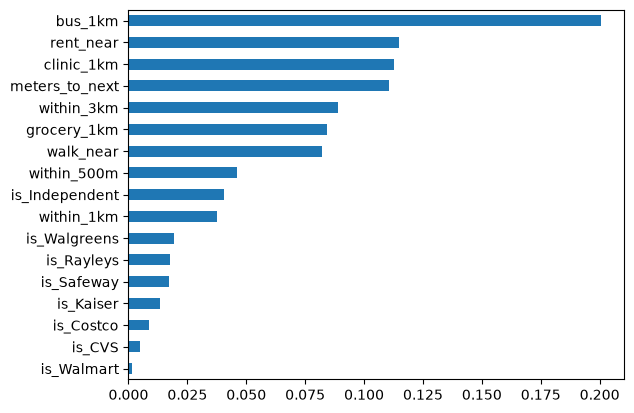

In [32]:
print(ev[ev.y == 0].nlargest(3, 'risk')[['name', 'lat', 'lon', 'risk']]) #rated risky, still open
print(ev[ev.y == 1].nsmallest(2, 'risk')[['name', 'lat', 'lon', 'risk']]) #rated safe, but closed

pd.Series(model.feature_importances_, index=features).sort_values().plot.barh() #which features mattered most

## Step 9. Map and charts
Owner: Brian  
Save charts to `FIG_DIR` and the folium map to `MAP_DIR`. Two-sided bars, 800 m before/after, model vs baseline, "last pharmacy standing" list.

In [33]:
# TODO (Brian)

## Step 10. Package
Owner: Ethan and Brian  
Restart and run all from the raw files. Update the README.

In [34]:
# TODO